<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/practical_4_Tushar_Guleria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Used the same dataset used in Practical 2:
 Question 1. Identify all duplicate cases using prof. Using all observations, find the average and standard deviation for age. Repeat the analysis by first filtering the data set to include one observation for each instructor with a total number of observations restricted to 94.

 Question 2. Using a bar chart, demonstrate if instructors teaching lower-division courses receive higher average teaching evaluations.

 Question 3. Plot the relationship between age and teaching evaluation scores.

  Question 4. Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores.
  
   Question 5. Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.

#Setup and Data Loading
 installing libraries ,Set visualization style, Load the dataset

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv("/content/TeachingRatings.csv")

**Question 1. Identify all duplicate cases using prof. Using all observations, find the average and standard deviation for age. Repeat the analysis by first filtering the data set to include one observation for each instructor with a total number of observations restricted to 94.**

The dataset contains 463 rows, where each row represents a course taught. Because one professor can teach multiple courses, an individual professor's ID (prof) can appear multiple times. We need to:

Find all repeated instructor entries.

Find the average and standard deviation of age using all 463 rows.

Remove duplicates so each of the 94 professors appears only once, and recalculate the age average and standard deviation.

In [3]:
# 1. Identify all rows where the professor ID appears more than once
duplicates = df[df.duplicated(subset=["prof"], keep=False)]
print(f"Total rows belonging to multi-course professors: {len(duplicates)}")

# 2. Statistics across ALL courses (463 rows)
mean_all = df["age"].mean()
std_all = df["age"].std()
print(f"All Courses (N = 463)  -> Mean Age: {mean_all:.2f}, Std Dev: {std_all:.2f}")

# 3. Filter down to 94 unique individual professors
unique_profs = df.drop_duplicates(subset=["prof"])

# 4. Statistics across UNIQUE professors (94 rows)
mean_unique = unique_profs["age"].mean()
std_unique = unique_profs["age"].std()
print(
    f"Unique Profs (N = 94)  -> Mean Age: {mean_unique:.2f}, Std Dev: {std_unique:.2f}"
)

Total rows belonging to multi-course professors: 456
All Courses (N = 463)  -> Mean Age: 48.37, Std Dev: 9.80
Unique Profs (N = 94)  -> Mean Age: 47.55, Std Dev: 10.26


Output & Explanation:

df.duplicated(subset=['prof'], keep=False): Scans the prof column and flags every row where an ID appears more than once.

df.drop_duplicates(subset=['prof']): Keeps only the first occurrence of each instructor ID, shrinking the table from 463 course rows to 94 instructor rows.

All Courses (463 observations): Mean Age = 48.37, Standard Deviation = 9.80

Unique Instructors (94 observations): Mean Age = 47.55, Standard Deviation = 10.26

Why do they differ? Older professors in this dataset teach slightly more classes on average than younger ones. When we look at every single course row, the older professors get counted multiple times, which slightly inflates the average age.

**Question 2. Using a bar chart, demonstrate if instructors teaching lower-division courses receive higher average teaching evaluations.**

/tmp/ipykernel_1560/3637153344.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=division_avg, x="division", y="eval", palette="Blues_d")


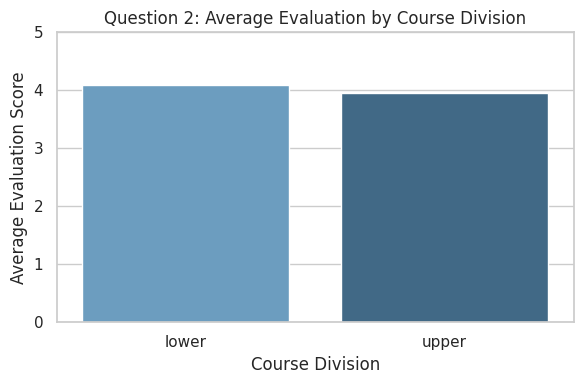

In [4]:
# 1. Group by division and calculate the mean evaluation score
division_avg = df.groupby("division")["eval"].mean().reset_index()

# 2. Plot the bar chart
plt.figure(figsize=(6, 4))
sns.barplot(data=division_avg, x="division", y="eval", palette="Blues_d")

# 3. Add chart titles, axis labels, and set y-axis from 0 to 5
plt.title("Question 2: Average Evaluation by Course Division")
plt.xlabel("Course Division")
plt.ylabel("Average Evaluation Score")
plt.ylim(0, 5)

# 4. Display the chart
plt.tight_layout()
plt.show()

Explanation of the Code & Findings:

df.groupby('division')['eval'].mean() splits the data into two buckets (lower and upper) and computes the average score for each.

Lower-division average: 4.09

Upper-division average: 3.95

Finding: Yes, instructors teaching lower-division courses receive slightly higher average ratings than those teaching upper-division courses.

**Question 3. Plot the relationship between age and teaching evaluation scores.**

We want to plot instructor age on the horizontal axis (X) and their teaching evaluation score eval on the vertical axis (Y) to see if ratings go up or down as instructors get older.

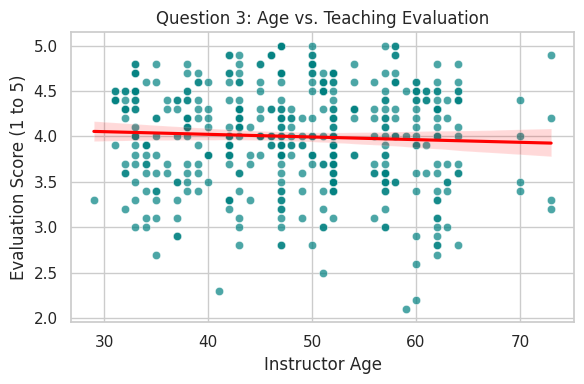

In [5]:
plt.figure(figsize=(6, 4))

# 1. Draw each course as a scatter dot
sns.scatterplot(data=df, x="age", y="eval", color="teal", alpha=0.7)

# 2. Add a linear regression line to show the general trend
sns.regplot(data=df, x="age", y="eval", scatter=False, color="red")

# 3. Label the plot
plt.title("Question 3: Age vs. Teaching Evaluation")
plt.xlabel("Instructor Age")
plt.ylabel("Evaluation Score (1 to 5)")
plt.tight_layout()
plt.show()

sns.scatterplot() plots every course evaluation as a point at coordinate (age, eval).

sns.regplot(scatter=False) fits a straight trendline through the points.

Finding: The trendline slopes slightly downward. This indicates a weak negative relationship: older instructors tend to receive slightly lower evaluation scores than younger instructors.

**Question 4. Using gender-differentiated scatter plots, plot the relationship between age and teaching evaluation scores.**

We take the previous scatter plot and color-code the points by gender (male vs. female) to see if male and female instructors have different rating patterns across age.

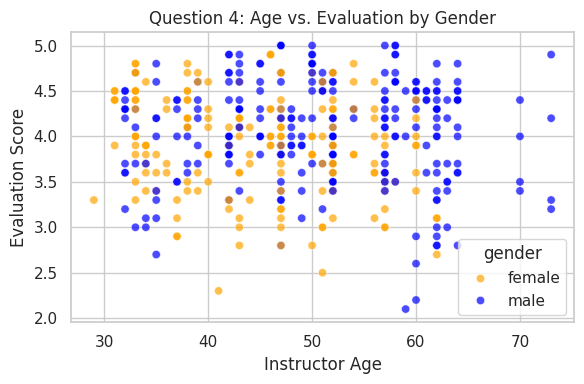

In [6]:
plt.figure(figsize=(6, 4))

# Use hue='gender' to color points differently based on gender
sns.scatterplot(
    data=df,
    x="age",
    y="eval",
    hue="gender",
    palette={"female": "orange", "male": "blue"},
    alpha=0.7,
)

plt.title("Question 4: Age vs. Evaluation by Gender")
plt.xlabel("Instructor Age")
plt.ylabel("Evaluation Score")
plt.tight_layout()
plt.show()

hue='gender' tells Seaborn to assign separate colors to female and male instructors.

Finding: Across most age groups, blue dots (male instructors) are clustered slightly higher on the score axis than orange dots (female instructors), indicating that male instructors receive higher average evaluation scores in this sample.

**Question 5. Create a scatterplot of age and evaluation scores, differentiated by gender and tenure.**

We need to visualize the relationship between age and eval while simultaneously showing both Gender (male vs. female) and Tenure (tenured vs. non-tenured).

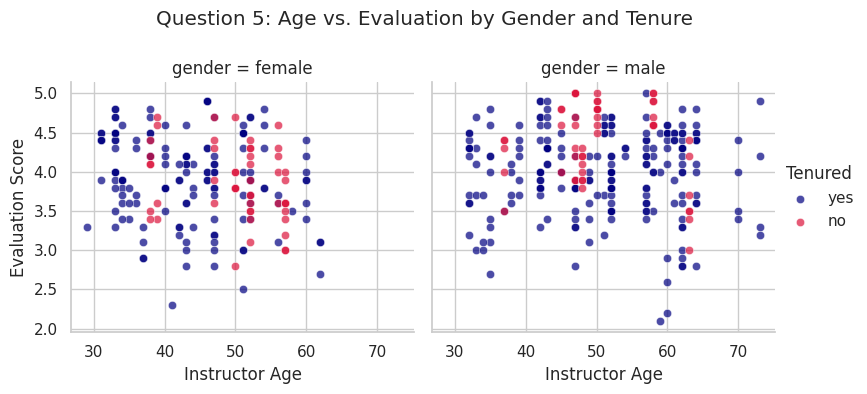

In [7]:
# 1. Create a side-by-side grid split by gender (one column for female, one for male)
g = sns.FacetGrid(
    df,
    col="gender",
    hue="tenure",
    palette={"yes": "navy", "no": "crimson"},
    height=4,
    aspect=1,
)

# 2. Map the scatter plot to both panels
g.map(sns.scatterplot, "age", "eval", alpha=0.7)

# 3. Add legend and titles
g.add_legend(title="Tenured")
g.set_axis_labels("Instructor Age", "Evaluation Score")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Question 5: Age vs. Evaluation by Gender and Tenure")

plt.show()

sns.FacetGrid(col="gender") splits the chart into two clean subplots side-by-side: Female on the left, Male on the right.

hue="tenure" colors tenured instructors in dark navy (yes) and non-tenured instructors in crimson (no).

Finding:

Non-tenured instructors (crimson) are concentrated at younger ages (< 50 years).

Tenured instructors (navy) span all ages up to 70+.

Male tenured professors maintain consistent ratings across broad age spans, whereas female ratings show slightly lower clusters overall.

Lab Practical Analysis: Teaching Ratings Dataset Summary
Phase 1: Environment Setup & Data Ingestion
Libraries Used: Loaded pandas for data manipulation/aggregation, and matplotlib.pyplot + seaborn for data visualization.

Dataset Ingestion: Read TeachingRatings.csv into a DataFrame containing 463 observations across 13 variables (such as prof, age, eval, division, gender, tenure).

Core Unit of Observation: Each row represents an individual course offering, meaning individual professors teaching multiple courses appear across several rows.

Phase 2: Duplicate Handling & Descriptive Statistics (Question 1)
Duplicate Identification:

Used df.duplicated(subset=['prof'], keep=False) to detect all rows corresponding to professors who taught more than one course.

Course-Level Summary (All 463 Rows):

Mean Age: 48.37 years

Standard Deviation: 9.80 years

Professor-Level Summary (Filtered to 94 Unique Instructors):

Applied df.drop_duplicates(subset=['prof']) to retain exactly one entry per professor.

Mean Age: 47.55 years

Standard Deviation: 10.26 years

Key Finding: The course-level age average is slightly higher because older faculty teach more courses on average within this sample.

Phase 3: Categorical Aggregation & Course Level Comparison (Question 2)
Objective: Compare average evaluation ratings between course divisions.

Method: Grouped observations by division and calculated the mean of eval, visualized via a vertical bar chart (sns.barplot).

Results:

Lower-division courses: 4.09 / 5.00

Upper-division courses: 3.95 / 5.00

Key Finding: Instructors teaching introductory (lower-division) courses receive slightly higher evaluation ratings compared to those teaching advanced (upper-division) courses.

Phase 4: Bivariate Relationship Analysis — Age vs. Ratings (Question 3)
Objective: Assess whether an instructor's age influences student evaluation scores.

Method: Generated a scatter plot (sns.scatterplot) of age (x-axis) vs. eval (y-axis) with an overlaid linear regression trendline (sns.regplot).

Key Finding: The fitted trendline displays a weak negative slope, indicating that older instructors tend to receive slightly lower evaluation scores than their younger counterparts.

Phase 5: Multivariate Demographic Breakdown (Questions 4 & 5)
Gender Differentiation (Question 4):

Plotted age vs. eval with color-coding applied via hue='gender'.

Finding: Male instructors' scores cluster higher across most age groups compared to female instructors.

Gender & Tenure Faceting (Question 5):

Constructed a multi-panel visual grid using sns.FacetGrid(col='gender', hue='tenure') to isolate the interactions among Age, Score, Gender, and Tenure status.

Findings:

Non-tenured faculty (tenure = 'no') are strictly clustered under 50 years of age.

Tenured faculty (tenure = 'yes') span across the full age spectrum (30–73 years).

Male tenured instructors maintain relatively high and consistent ratings across all age brackets.